In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
from matplotlib import pyplot as plt

import utilities as ut
import numpy as np
from theme import set_theme
from utilities import plot_equity_curve

set_theme()

{'rc_params': {'figure.facecolor': '#fcfcfb',
  'axes.facecolor': '#fcfcfb',
  'savefig.facecolor': '#fcfcfb',
  'axes.edgecolor': '#898781',
  'axes.labelcolor': '#52514e',
  'axes.titlecolor': '#0b0b0b',
  'axes.titlelocation': 'left',
  'axes.titlesize': 11,
  'axes.titleweight': 'bold',
  'axes.spines.top': False,
  'axes.spines.right': False,
  'text.color': '#0b0b0b',
  'xtick.color': '#52514e',
  'ytick.color': '#52514e',
  'axes.grid': True,
  'axes.grid.axis': 'y',
  'grid.color': '#e6e5e1',
  'grid.linewidth': 0.8,
  'grid.linestyle': '-',
  'lines.linewidth': 1.8,
  'legend.frameon': False,
  'font.size': 9.5,
  'text.parse_math': False},
 'palette': ['#2a78d6',
  '#eb6834',
  '#1baf7a',
  '#eda100',
  '#e87ba4',
  '#008300',
  '#4a3aa7',
  '#e34948'],
 'colors': {'surface': '#fcfcfb',
  'ink': '#0b0b0b',
  'ink_secondary': '#52514e',
  'muted': '#898781',
  'grid': '#e6e5e1',
  'neutral': '#f0efec',
  'palette': ['#2a78d6',
   '#eb6834',
   '#1baf7a',
   '#eda100',
   '#e87

In [2]:
# Test Delphic Alpha feature set
BEAN_PATH = r"C:\Users\Amin\PycharmProjects\Asia Ags\data\raw\dce_bean_data.parquet"
bean = pd.read_parquet(BEAN_PATH)
MEAL_PATH = r"C:\Users\Amin\PycharmProjects\Asia Ags\data\raw\dce_meal_data.parquet"
meal = pd.read_parquet(MEAL_PATH)

# combine
df = pd.merge_asof(bean.sort_index(), meal.sort_index(), left_index=True, right_index=True, direction="backward")
df

,date_x,close_x,volume_x,hold_x,contract_x,date_y,close_y,volume_y,hold_y,contract_y
0,2018-05-16,3399.0,32,24,B1905,2018-05-16,2897.0,49778,41652,M1905
1,2018-05-17,3430.0,8,28,B1905,2018-05-17,2879.0,27796,58382,M1905
2,2018-05-18,3410.0,20,40,B1905,2018-05-18,2864.0,31498,72788,M1905
3,2018-05-21,3391.0,1664,1658,B1905,2018-05-21,2831.0,68988,108104,M1905
4,2018-05-22,3390.0,1678,96,B1905,2018-05-22,2841.0,26058,116728,M1905
...,...,...,...,...,...,...,...,...,...,...
5612,2026-09-23,3877.0,10,74,B2709,2026-04-23,3036.0,52396,240555,M2701
5613,2026-09-24,3871.0,93,126,B2709,2026-04-24,3023.0,85160,261383,M2701
5614,2026-09-28,3828.0,25,126,B2709,2026-04-27,3035.0,38121,262102,M2701
5615,2026-09-29,3837.0,27,128,B2709,2026-04-28,3047.0,33030,264652,M2701


In [3]:
# build log returns
ts = ut.log_transform(df, cols=["close_y", "close_x"])
ts = ts.rename(columns={"close_y_log_return": "meal_log_ret", "close_x_log_return": "bean_log_ret"})


In [11]:
wheat = r"C:\Users\Amin\PycharmProjects\Asia Ags\data\raw\wheat_usd_15m.csv"
beans = r"C:\Users\Amin\PycharmProjects\Asia Ags\data\raw\soybn_usd_15m.csv"

wheat = pd.read_csv(wheat)
wheat["timestamp"] = pd.to_datetime(wheat["timestamp"])
wheat = wheat.set_index("timestamp").sort_index()

tf = wheat.resample("30min").agg({
    "open": "first",
    "high": "max",
    "low": "min",
    "close": "last",
    "volume": "sum",
}).dropna()


In [5]:

frame = pd.read_csv(beans)
frame["timestamp"] = pd.to_datetime(frame["timestamp"])
frame = frame.set_index("timestamp").sort_index()

frame = frame.resample("30min").agg({
    "open": "first",
    "high": "max",
    "low": "min",
    "close": "last",
    "volume": "sum",
}).dropna()

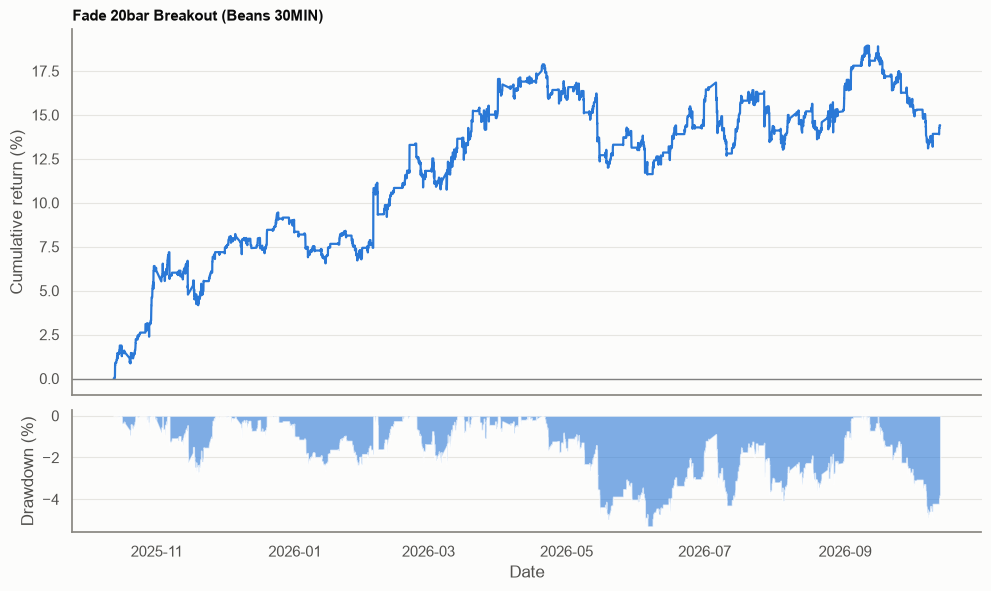

position
 0.0    6847
-1.0    1165
 1.0     924
Name: count, dtype: int64

In [13]:
fade = ut.fade_breakout(frame, window=20)
ret = fade["strategy_return"]
ut.plot_equity_curve(ret, "Fade 20bar Breakout (Beans 30MIN)")
